In [1]:
import os
import pandas as pd
import datajoint as dj
# from datetime import datenid
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\_distributor_init.py:32: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.PYQHXLVVQ7VESDPUVUADXEVJOBGHJPAY.gfortran-win_amd64.dll
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.XWYDX2IKJW2NMTWSFYNGFUWKQU3LYTCZ.gfortran-win_amd64.dll
  stacklevel=1)


In [ ]:
import matplotlib.colors


color_sSC = matplotlib.colors.to_rgba('#de8f05') ##de8f05')
color_dSC = matplotlib.colors.to_rgba('#d55e00')
color_LP = matplotlib.colors.to_rgba('#029e73')

color_CTRL = matplotlib.colors.to_rgba('#949494')
color_NTSR = matplotlib.colors.to_rgba('#0173b2')
color_GRP = matplotlib.colors.to_rgba('#cc78bc')

color_all = color_CTRL # matplotlib.colors.to_rgba('#9E9E9E')
color_opto = color_GRP # matplotlib.colors.to_rgba('#C84B31') # color NTSR

colors = [color_all, color_opto, color_opto]
linestyles = ['-', '-', '-']
from matplotlib.markers import MarkerStyle
pointstyles = [MarkerStyle('o', fillstyle='full'), MarkerStyle('o', fillstyle='full'),MarkerStyle('o', fillstyle='full')]

import matplotlib as mpl
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.bottom'] = True

plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['lines.linewidth'] = 0.75
plt.rcParams['lines.markersize'] = 2.0
plt.rcParams['patch.linewidth'] = 1.0
plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 0.5
plt.rcParams['xtick.minor.width'] = 0.5
plt.rcParams['ytick.minor.width'] = 0.5
plt.rcParams['xtick.major.size'] = 3.5
plt.rcParams['ytick.major.size'] = 3.5
plt.rcParams['xtick.minor.size'] = 2.0
plt.rcParams['ytick.minor.size'] = 2.0

mpl.rcParams['font.size'] = 8
mpl.rcParams['axes.titlesize'] = 8
mpl.rcParams['axes.labelsize'] = 8
mpl.rcParams['xtick.labelsize'] = 6
mpl.rcParams['ytick.labelsize'] = 6
mpl.rcParams['legend.fontsize'] = 6
mpl.rcParams['legend.title_fontsize'] = 6
mpl.rcParams['legend.fontsize'] = 6

mpl.rcParams['font.family'] = "sans-serif"
mpl.rcParams['font.sans-serif'] = "Arial"
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

cm = 1/2.54 # centimeters in inches

fig_path = r''

### Data

In [ ]:
import datasets

ds = datasets.get_dataset('population_coding', as_keys=True)
SC_recs_dict = ds['SC']
LP_recs_dict = ds['LP']


In [ ]:
stim_types = ['EXPA', 'EXPA_60', 'EXPA_25', 'EXPW', 'EXPW_60','DIMM']


In [ ]:
from datajoint_utils import get_cluster_frs

sSC_dict = get_cluster_frs([], stim_types, dataset_name='sSC_VR_all_fr25_20260116', means=False, subsession_id='01', fix_sweeping=False)
dSC_dict = get_cluster_frs([], stim_types, dataset_name='dSC_VR_all_fr25_20260116', means=False, subsession_id='01', fix_sweeping=False)
LP_dict = get_cluster_frs([], stim_types, dataset_name='LP_VR_all_fr25_20260116', means=False, subsession_id='01', fix_sweeping=False)

sSC_frs, sSC_depths, sSC_keys_used = sSC_dict['cluster_frs'], sSC_dict['cluster_depths'], sSC_dict['cluster_keys']
dSC_frs, dSC_depths, dSC_keys_used = dSC_dict['cluster_frs'], dSC_dict['cluster_depths'], dSC_dict['cluster_keys']
LP_frs, LP_depths, LP_keys_used = LP_dict['cluster_frs'], LP_dict['cluster_depths'], LP_dict['cluster_keys']
sum([len(v) for k,v in sSC_frs.items()]), sum([len(v) for k,v in dSC_frs.items()]), sum([len(v) for k,v in LP_frs.items()])

sSC: 1414 , dSC: 1613 , LP: 782
Found data locally, loading...
Found data locally, loading...
Found data locally, loading...


(1245, 1113, 696)

In [ ]:
def filter_exp_dict(frs, depths, keys_used, filter=None):
    frs_filt, depths_filt, keys_used_filt = {}, {}, {}
    for exp_key, cl_keys in keys_used.items():
        for i, cl_key in enumerate(cl_keys):
            response_times, response_prob = (opto_cluster_table & cl_key).fetch('median_response_time', 'response_prob')
            if len(response_times) == 0:
                continue 
            response_time_ms = np.min(response_times)
            if filter == 'early':
                early_label_filter= '(response_prob > 0.1)'
                cl_key_full = (opto_curation_table & cl_key & early_label_filter).fetch('KEY')
                if (len(cl_key_full) > 0) and (response_time_ms < 9):
                    if exp_key not in keys_used_filt:
                        keys_used_filt[exp_key] = []
                        frs_filt[exp_key] = []
                        depths_filt[exp_key] = []
                    frs_filt[exp_key].append(frs[exp_key][i])
                    depths_filt[exp_key].append(depths[exp_key][i])
                    keys_used_filt[exp_key].append(cl_key)
            elif filter == 'late':
                cl_key_full = (opto_curation_table & cl_key).fetch('KEY')
                if (len(cl_key_full) > 0) and (response_time_ms >= 9):
                    if exp_key not in keys_used_filt:
                        keys_used_filt[exp_key] = []
                        frs_filt[exp_key] = []
                        depths_filt[exp_key] = []
                    frs_filt[exp_key].append(frs[exp_key][i])
                    depths_filt[exp_key].append(depths[exp_key][i])
                    keys_used_filt[exp_key].append(cl_key)
            else:
                cl_key_full = (opto_curation_table & cl_key).fetch('KEY')
                if len(cl_key_full) > 0:
                    if exp_key not in keys_used_filt:
                        keys_used_filt[exp_key] = []
                        frs_filt[exp_key] = []
                        depths_filt[exp_key] = []
                    frs_filt[exp_key].append(frs[exp_key][i])
                    depths_filt[exp_key].append(depths[exp_key][i])
                    keys_used_filt[exp_key].append(cl_key)
        if exp_key in frs_filt.keys():
            frs_filt[exp_key] = np.array(frs_filt[exp_key])
            depths_filt[exp_key] = np.array(depths_filt[exp_key])
            keys_used_filt[exp_key] = np.array(keys_used_filt[exp_key])
    return frs_filt, depths_filt, keys_used_filt

late_frs, late_depths, late_keys_used = filter_exp_dict(dSC_frs, dSC_depths, dSC_keys_used, filter='late')
all_frs, all_depths, all_keys_used = dSC_frs, dSC_depths, dSC_keys_used
early_frs, early_depths, early_keys_used = filter_exp_dict(dSC_frs, dSC_depths, dSC_keys_used, filter='early')

# late_frs, late_depths, late_keys_used = filter_exp_dict(LP_frs, LP_depths, LP_keys_used, filter='late')
# all_frs, all_depths, all_keys_used = LP_frs, LP_depths, LP_keys_used
# early_frs, early_depths, early_keys_used = filter_exp_dict(LP_frs, LP_depths, LP_keys_used, filter='early')


In [15]:
print('all: ', len(all_keys_used), len(np.concatenate([val for key, val in all_keys_used.items()])))
print('early: ', len(early_keys_used), len(np.concatenate([val for key, val in early_keys_used.items()])))
print('late: ', len(late_keys_used), len(np.concatenate([val for key, val in late_keys_used.items()])))


all:  24 1050
early:  6 42
late:  8 50


In [18]:
# Get means
for key in late_frs:
    late_frs[key] = np.nanmean(late_frs[key][:,:,:], axis=2)
    # baseline subtraction
    late_frs[key] = late_frs[key] - np.nanmean(late_frs[key][:,:,50:350], axis=2, keepdims=True)
for key in all_frs:
    all_frs[key] = np.nanmean(all_frs[key][:,:,:], axis=2)
    all_frs[key] = all_frs[key] - np.nanmean(all_frs[key][:,:,50:350], axis=2, keepdims=True)
for key in early_frs:
    early_frs[key] = np.nanmean(early_frs[key][:,:,:], axis=2)
    early_frs[key] = early_frs[key] - np.nanmean(early_frs[key][:,:,50:350], axis=2, keepdims=True)


### Code

In [21]:
def get_stim_idxs(stim, stim_types):
    return stim_types.index(stim)

In [ ]:
import pandas as pd


def get_stimcomp_df(compstims, windows):
    compstims_idxs = [get_stim_idxs(stim, stim_types) for stim in compstims]

    # Create dataframe with max median frs
    early_df = pd.DataFrame(columns=compstims)
    late_df = pd.DataFrame(columns=compstims)
    all_df = pd.DataFrame(columns=compstims)

    start, end = 400, 400+100 # 400, 400+100

    for key, frs_curr in early_frs.items():
        frs_curr = np.array(frs_curr)
        print(frs_curr.shape)
        for frs_curr_cluster in frs_curr:
            print(frs_curr_cluster.shape)
            early_dict = {stim: np.percentile(frs_curr_cluster[stim_idx,start:end], 98) for stim_idx, stim, (start, end) in zip(compstims_idxs, compstims, windows)}
            early_df = early_df.append(early_dict, ignore_index=True)
    for key, frs_curr in late_frs.items():
        frs_curr = np.array(frs_curr)
        for frs_curr_cluster in frs_curr:
            late_dict = {stim: np.percentile(frs_curr_cluster[stim_idx,start:end], 98) for stim_idx, stim, (start, end) in zip(compstims_idxs, compstims, windows)}
            late_df = late_df.append(late_dict, ignore_index=True)
    for key, frs_curr in all_frs.items():
        frs_curr = np.array(frs_curr)
        for frs_curr_cluster in frs_curr:
            all_dict = {stim: np.percentile(frs_curr_cluster[stim_idx,start:end], 98) for stim_idx, stim, (start, end) in zip(compstims_idxs, compstims, windows)}
            all_df = all_df.append(all_dict, ignore_index=True)

    print(early_df)

    early_df_norm = early_df.div(np.max(early_df, axis=1), axis=0)
    late_df_norm = late_df.div(np.max(late_df, axis=1), axis=0)
    all_df_norm = all_df.div(np.max(all_df, axis=1), axis=0)

    early_df_norm = early_df_norm.melt(var_name='stim', value_name='response')
    late_df_norm = late_df_norm.melt(var_name='stim', value_name='response')
    all_df_norm = all_df_norm.melt(var_name='stim', value_name='response')
    early_df_norm['area'] = 'early'
    late_df_norm['area'] = 'late'
    all_df_norm['area'] = 'all'

    all_df = pd.concat([early_df_norm, late_df_norm, all_df_norm])

    return all_df


In [ ]:
swep_stims = ['SWEP_4', 'SWEP_12', 'SWEP_20']
swep_stims_labels = ['sweeping 4', 'sweeping 12', 'sweeping 20']
windows = [(400, 400+200*4), (400, 400+200*4), (400, 400+200*4), (400, 400+200*4)]
all_df_swep = get_stimcomp_df(swep_stims, windows)

constrast_stims = ['EXPW', 'EXPW_60', 'EXPA_25', 'EXPA_60', 'EXPA', 'DIMM']
contrast_stims_labels = ['expa white 100%', 'expa white 60%', 'expa black 25%', 'expa black 60%', 'expa black 100%', 'dimming']

windows = [(400, 400+100), (400, 400+100), (400, 400+100), (400, 400+100), (400, 400+100), (400, 400+100)]
all_df_contrast = get_stimcomp_df(constrast_stims, windows)

main_stims = ['EXPW', 'EXPA', 'DIMM']
main_stims_labels = ['expa white 100%', 'expa black 100%', 'dimming']
windows = [(400, 400+100), (400, 400+100), (400, 400+100)]
all_df_main = get_stimcomp_df(main_stims, windows)

(3, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(10, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(6, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(70, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 20

In [24]:
cmap = sb.color_palette("tab10")
def get_percentiles(vec):
    return np.percentile(vec, [25, 75])

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\seaborn\categorical.py:1731: UserWarning: You passed a edgecolor/edgecolors ((0.00392156862745098, 0.45098039215686275, 0.6980392156862745)) for an unfilled marker (<matplotlib.markers.MarkerStyle object at 0x00000227096DD608>).  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  zorder=z)
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\seaborn\categorical.py:1731: UserWarning: You passed a edgecolor/edgecolors ((0.00392156862745098, 0.45098039215686275, 0.6980392156862745)) for an unfilled marker (<matplotlib.markers.MarkerStyle object at 0x00000227096DD608>).  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  zorder=z)
meta NOT subset; don't know how to subset; dropped


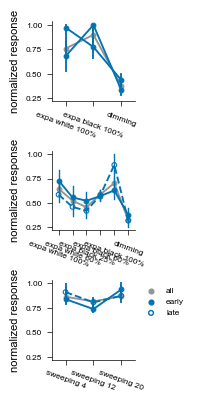

In [29]:
# estimator=np.median, errorbar=get_percentiles
colors = [color_all, color_opto, color_opto]
linestyles = ['-', '-', '--']
# pointstyles = ["o", "$\circ$", "s"]
from matplotlib.markers import MarkerStyle
# pointstyles = [MarkerStyle('o', fillstyle='full'), MarkerStyle('o', fillstyle='none')]
pointstyles = [MarkerStyle('o', fillstyle='full'), MarkerStyle('o', fillstyle='full'),MarkerStyle('o', fillstyle='none')]
mew_val = 0.8  # Makes the open circle outline thinner
err_lw = 1.0  # Makes the error bars thinner

# get rid of nan values
all_df_swep = all_df_swep.dropna()
all_df_contrast = all_df_contrast.dropna()
all_df_main = all_df_main.dropna()

fig, axs= plt.subplots(3, 1, figsize=(5*cm,10*cm), sharey=True)
sb.pointplot(data=all_df_main, x='stim', y='response', hue="area", ax=axs[0], palette=colors, hue_order=["all", "early", "late"], estimator=np.median, errorbar='ci')
axs[0].set(xticklabels=main_stims_labels, xlabel='', ylabel='normalized response')
# Change x label orientation
plt.setp(axs[0].get_xticklabels(), rotation=-20)
axs[0].legend().set_visible(False)
sb.pointplot(data=all_df_contrast, x='stim', y='response', hue="area", ax=axs[1], palette=colors, linestyles=linestyles, markers=pointstyles, hue_order=["all", "early", "late"], estimator=np.median, errorbar='ci', errwidth=err_lw)
axs[1].set(xticklabels=contrast_stims_labels, xlabel='', ylabel='normalized response')
plt.setp(axs[1].get_xticklabels(), rotation=-20)
# axs[1].legend(bbox_to_anchor=(1, 1), frameon=False)
axs[1].legend().set_visible(False)
sb.pointplot(data=all_df_swep, x='stim', y='response', hue="area", ax=axs[2], palette=colors, linestyles=linestyles, markers=pointstyles, hue_order=["all", "early", "late"], estimator=np.median, errorbar='ci')
axs[2].set(xticklabels=swep_stims_labels, xlabel='', ylabel='normalized response')
axs[2].legend(bbox_to_anchor=(1, 1), frameon=False)
plt.setp(axs[2].get_xticklabels(), rotation=-20)
for ax in axs:
    for collection in ax.collections:
        collection.set_linewidths(0.8)
plt.tight_layout()
plt.savefig(os.path.join(fig_path, 'population_differences_units_medianci_082026.pdf'), bbox_inches='tight', dpi=300)
# plt.savefig(rf'E:\OneDrive - imec\VEIDB - FarrowLab-Colab\Manuscript\Figures\Ephys\raw\population_differences_units_medianci_042025.pdf', bbox_inches='tight', dpi=300)

plt.show()